# External same-species gallery expansion: CLIP and DINOv2 E1–E4

**Objective / question:** how do the fixed representations withstand 100–500 external same-species photographs?
**Hypothesis:** adding unrelated photographs reduces retrieval accuracy; adaptation can change that degradation differently across domains.
**Intervention:** nested Oxford-IIIT Pet photographs. **Controls:** unchanged checkpoints, queries, original galleries and preprocessing. **Sample:** 277 public / 502 private queries; 500 cat and 500 dog distractor photos.
**Training / selection:** none; reuse previous validation-selected checkpoints. **Metrics:** Rank-1, photo mAP, external top-1 rate, paired identity-bootstrap intervals. **Results:** generated below, not assumed. **Limitations:** photo proxies are not verified identities, pretraining overlap unknown, fixed-gallery retrospective closed-set sensitivity, no session-disjoint claim.

External methods: Parkhi et al., *Cats and Dogs*, CVPR 2012 (https://www.robots.ox.ac.uk/~vgg/data/pets/); Radford et al., CLIP; Oquab et al., DINOv2; Hu et al., LoRA. Sampling, composition, gallery expansion and paired comparisons are this study's design choices. See `docs/external_distractors_protocol.md` for the locked protocol.

## Fase 1. Data preparation / preprocessing
Load the separately prepared release from `datasets/`; verify hashes without changing its selection. Original public and private galleries stay separate.

In [ ]:
# Runtime guard added after the recorded execution; historical outputs are unchanged.
import sys
if not (3, 11) <= sys.version_info[:2] < (3, 14):
    raise RuntimeError("Python 3.11–3.13 required")


In [1]:
from pathlib import Path
import gc, hashlib, json, time, os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"  # CPU fallback for DINO positional bicubic interpolation.
import numpy as np
import torch
from PIL import Image, ImageOps
from dotenv import load_dotenv
from pettrace.data.verification import sha256
from pettrace.tracking import production_context
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
REPORT = ROOT / 'reports/external-distractors-20261120'
PREP = ROOT / 'datasets/build/oxford-distractors-20261120/manifest.json'
load_dotenv(ROOT / '.env'); load_dotenv(ROOT / '.env.local')
LOG_TO_MLFLOW = True  # Publication is mandatory; this is not a switch.
client, experiment = production_context()
lock = json.loads((REPORT / 'protocol-lock.json').read_text())
assert sha256(ROOT / lock['protocol']) == lock['sha256']
manifest = json.loads(PREP.read_text())
assert manifest['commit'] == '089695c834a7deb60505b7cc506672db1c31a6aa'
rows = manifest['benchmark'] + manifest['distractors']
assert len(rows) == 1779 and len({r['sha256'] for r in rows}) == 1779
assert [sum(r['domain']==d for r in rows) for d in ('public','private','oxford')] == [277,502,1000]
for r in rows: assert sha256(ROOT / r['path']) == r['sha256']
input_hash = sha256(PREP)
(REPORT / 'prepared-input.json').write_text(json.dumps(manifest, indent=2))
print('Verified 277 public, 502 private, 500 cat and 500 dog Oxford photographs.')
receipt_path = REPORT / 'publication.json'
if receipt_path.exists():
    publication = json.loads(receipt_path.read_text())
    assert publication['input_sha256'] == input_hash
else:
    run_id = client.create_run(experiment.experiment_id, tags={'mlflow.runName':'Oxford external distractors · CLIP/DINO E1–E4', 'experiment':'external-distractors', 'purpose':'evaluation', 'scope':'exploratory closed-set gallery expansion'}).info.run_id
    publication = dict(run_id=run_id, input_sha256=input_hash, published=False)
    receipt_path.write_text(json.dumps(publication,indent=2))
run_id = publication['run_id']
client.log_param(run_id, 'protocol_sha256', lock['sha256'])
client.log_param(run_id, 'oxford_commit', manifest['commit'])
client.log_param(run_id, 'distractors_per_species', '0,100,250,500')
client.log_artifact(run_id, str(ROOT / lock['protocol']), 'protocol')
client.log_artifact(run_id, str(REPORT / 'prepared-input.json'), 'report')


2026/11/20 08:30:39 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/alessandro/Develop/personal/pettrace-ml/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Verified 277 public, 502 private, 500 cat and 500 dog Oxford photographs.


## Fase 2. Representation / training
No training. Reuse original CLIP ONNX artifacts and the DINOv2 sequential research bundle. Record hashes and cache each extraction batch for restart. Check golden outputs and original-gallery metrics before interpreting stress-test outcomes.

In [2]:
from pettrace.models.artifacts import load_model
from pettrace.models.golden import golden_images, compare
from pettrace.training import triplet, lora
from pettrace.training.dinov2 import build, Config, Pipeline as DinoPipeline

def features(name, pipeline, identity):
    folder = REPORT / 'features' / name
    folder.mkdir(parents=True,exist_ok=True)
    signature = dict(model=identity, input_sha256=input_hash)
    key = hashlib.sha256(json.dumps(signature,sort_keys=True).encode()).hexdigest()
    (folder / 'identity.json').write_text(json.dumps(signature,indent=2))
    parts = []; start = time.monotonic()
    for offset in range(0,len(rows),16):
        path = folder / f'{key}-{offset}.npy'; checksum = path.with_suffix('.sha256')
        if path.exists() and checksum.exists():
            assert sha256(path) == checksum.read_text()
            values = np.load(path,allow_pickle=False)
        else:
            images=[]
            for r in rows[offset:offset+16]:
                with Image.open(ROOT/r['path']) as im: images.append(ImageOps.exif_transpose(im).convert('RGB'))
            values = pipeline.embed(images)
            np.save(path,values); checksum.write_text(sha256(path))
        assert values.ndim == 2 and len(values) == len(rows[offset:offset+16]) and np.isfinite(values).all()
        assert np.allclose(np.linalg.norm(values,axis=1),1,atol=1e-4)
        parts.append(values)
        if offset % 160 == 0: print(name,offset+len(values),'/',len(rows),f'{time.monotonic()-start:.1f}s',flush=True)
    result = np.concatenate(parts)
    np.save(REPORT / f'{name}.npy',result)
    (REPORT / f'{name}-provenance.json').write_text(json.dumps(dict(**signature,features_sha256=sha256(REPORT/f'{name}.npy'),wall_seconds_this_invocation=time.monotonic()-start),indent=2))
    return result

embeddings = {}
base_dir = ROOT / 'reports/clip-e1-e2-v6-20261119-control/models'
models = {}
for name, path, uri in [('CLIP-E1',base_dir/'e1','models:/pettrace-embedder/1'),('CLIP-E2',base_dir/'e2','models:/pettrace-embedder/2'),('CLIP-E4',REPORT/'models/model','models:/pettrace-embedder/23')]:
    model = load_model(path); assert model.golden_ok
    identity = dict(uri=uri,hashes=model.sha256,pipeline_sha256=sha256(path/'pipeline.yaml'),golden_ok=True)
    models[name] = identity
    embeddings[name] = features(name,model.pipeline,identity)
    if name == 'CLIP-E2': detector = model.pipeline.detector
    del model; gc.collect()
head_path = ROOT / 'reports/e4-sampling-session/backups/e4_sampling_backup_20261118T080707Z/head.pt'
head = lora.load_frozen_e3_head(head_path,'4ff76c5f79bd1acaf6a8732905ee69bcaf9c93983d1e3332142965f18c2cb4ed')
embeddings['CLIP-E3'] = triplet.project(head,embeddings['CLIP-E2'])
models['CLIP-E3'] = dict(parent=models['CLIP-E2'],head_sha256=sha256(head_path))
np.save(REPORT/'CLIP-E3.npy',embeddings['CLIP-E3'])
print('CLIP representations complete.',flush=True)


CLIP-E1 16 / 1779 0.0s


CLIP-E1 176 / 1779 0.0s


CLIP-E1 336 / 1779 0.0s


CLIP-E1 496 / 1779 0.0s


CLIP-E1 656 / 1779 0.0s


CLIP-E1 816 / 1779 0.0s


... (27 outputs left out)

CLIP-E4 1456 / 1779 0.0s


CLIP-E4 1616 / 1779 0.0s


CLIP-E4 1776 / 1779 0.0s


CLIP representations complete.


In [3]:
device = 'mps' if torch.backends.mps.is_available() else 'cpu'
bundle = ROOT / 'reports/dino-sequential/20261119-v1/research-model'
bundle_spec = json.loads((bundle/'model.json').read_text())
from huggingface_hub import snapshot_download
snapshot = Path(snapshot_download(bundle_spec['repository'],revision=bundle_spec['revision'],local_files_only=True))
for name in ('model.safetensors','config.json','preprocessor_config.json'):
    assert sha256(snapshot/name) == bundle_spec['base_hashes'][name]
assert models['CLIP-E2']['hashes']['detector.onnx'] == bundle_spec['base_hashes']['detector.detector.onnx']
encoder, processor = build('frozen',device)
for stage, crop in [('E1',None),('E2',detector)]:
    identity = dict(backbone=bundle_spec['base_hashes'],crop=stage=='E2',device=device)
    name='DINOv2-'+stage
    embeddings[name] = features(name,DinoPipeline(encoder,processor,crop,batch=4),identity)
    models[name]=identity
saved = torch.load(bundle/'head.pt',map_location='cpu',weights_only=True)
head = triplet.Head(saved['config']['hidden'],dimension=saved['dimension'])
head.load_state_dict(saved['state_dict']); head.eval().requires_grad_(False)
embeddings['DINOv2-E3'] = triplet.project(head,embeddings['DINOv2-E2'])
models['DINOv2-E3'] = dict(parent=models['DINOv2-E2'],head_sha256=sha256(bundle/'head.pt'))
np.save(REPORT/'DINOv2-E3.npy',embeddings['DINOv2-E3'])
del encoder;gc.collect()
if device=='mps':torch.mps.empty_cache()
encoder,processor=build('mlp_lora',device,Config(seed=47),head=head)
lora.load_adapter(encoder,bundle/'adapter.pt')
pipeline=DinoPipeline(encoder,processor,detector,batch=4)
fresh=pipeline.embed(golden_images()); stored=np.load(bundle/'golden.npy')
golden_ok,_,_=compare(stored,fresh)
assert golden_ok, 'DINO cross-device golden comparison failed'
identity=dict(parent=models['DINOv2-E3'],adapter_sha256=sha256(bundle/'adapter.pt'),golden_ok=golden_ok,device=device)
embeddings['DINOv2-E4']=features('DINOv2-E4',pipeline,identity)
models['DINOv2-E4']=identity
(REPORT/'models.json').write_text(json.dumps(models,indent=2))
del encoder,pipeline;gc.collect()
if device=='mps':torch.mps.empty_cache()
print('All eight fixed representations complete.',flush=True)


/Users/alessandro/Develop/personal/pettrace-ml/.venv/lib/python3.11/site-packages/torch/nn/functional.py:4594: UserWarning: The operator 'aten::upsample_bicubic2d.out' is not currently supported on the MPS backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/mps/MPSFallback.mm:13.)
  return torch._C._nn.upsample_bicubic2d(


DINOv2-E1 16 / 1779 0.5s


DINOv2-E1 176 / 1779 4.9s


DINOv2-E1 336 / 1779 9.5s


DINOv2-E1 496 / 1779 14.9s


DINOv2-E1 656 / 1779 20.2s


... (28 outputs left out)

DINOv2-E4 1456 / 1779 78.7s


DINOv2-E4 1616 / 1779 86.9s


DINOv2-E4 1776 / 1779 95.1s


All eight fixed representations complete.


## Fase 3. Evaluation / analysis
Only original queries are scored; external photos serve solely as negatives. Rank-1 equals identity-level max aggregation without requiring external identity counts. mAP remains photo-level. Report numerical reproduction checks, deterioration curves, per-query results and cluster intervals. Publication is mandatory and resumable.

In [4]:
from pettrace.evaluation.metrics import retrieval
from pettrace.evaluation.paired import paired_comparison

def expanded(features, domain, count):
    qidx=[i for i,r in enumerate(rows) if r['domain']==domain]
    per=[]
    for sp in ('cat','dog'):
        original=[i for i in qidx if rows[i]['species']==sp]
        external=[i for i,r in enumerate(rows) if r['domain']=='oxford' and r['species']==sp][:count]
        for q in original:
            gallery=[i for i in original if i!=q]+external
            scores=np.clip(features[q] @ features[gallery].T,-1,1)
            order=np.argsort(-scores,kind='stable')
            own=np.array([rows[i]['animal']==rows[q]['animal'] for i in gallery])[order]
            assert own.any()
            positions=np.flatnonzero(own)+1
            ap=float(np.mean(np.arange(1,len(positions)+1)/positions))
            # Rank is used only to encode hit/miss; external individual IDs are unknown.
            hit=bool(own[0]); top=gallery[int(order[0])]
            per.append(dict(query=q,animal=rows[q]['animal'],species=sp,photo=rows[q]['path'],rank=1 if hit else 2,ap=ap,external_top1=rows[top]['domain']=='oxford',top_photo=rows[top]['path'],gallery_photos=len(gallery),gallery_animals=len({rows[i]['animal'] for i in original})))
    summary={}
    for sp in ('global','cat','dog'):
        subset=per if sp=='global' else [r for r in per if r['species']==sp]
        summary[sp]=dict(queries=len(subset),rank1=float(np.mean([r['rank']==1 for r in subset])),mAP=float(np.mean([r['ap'] for r in subset])),external_top1=float(np.mean([r['external_top1'] for r in subset])))
    return dict(protocol='zero-shot',test=dict(**summary,per_query=per),external_photos_per_species=count,rank_encoding='binary hit/miss; not full identity rank')

# Non-trivial metric check: no distractors must agree with the shared evaluator,
# and adding negatives cannot improve AP or Rank-1 on any query.
source_manifest=json.loads((ROOT/'reports/distractor-sensitivity-20261120/input-manifest.json').read_text())
results={}; reproduction=[]
for name, values in embeddings.items():
    assert values.shape[0]==1779
    for domain in ('public','private'):
        key=name+'/'+domain
        result={str(k):expanded(values,domain,k) for k in (0,100,250,500)}
        idx=[i for i,r in enumerate(rows) if r['domain']==domain]
        shared=retrieval(values[idx],[rows[i]['animal'] for i in idx],[rows[i]['species'] for i in idx])
        for metric in ('rank1','mAP'): assert abs(shared['global'][metric]-result['0']['test']['global'][metric])<1e-6
        src=next(x for x in source_manifest if x['domain']==domain and x['model']==name.replace('-',' '))
        assert sha256(ROOT/src['path'])==src['sha256']
        old=json.loads((ROOT/src['path']).read_text());old=old.get('result',old)
        delta={m:result['0']['test']['global'][m]-old['test']['global'][m] for m in ('rank1','mAP')}
        # Backend tolerance: Rank-1 must match exactly; mAP may differ < 0.01 pp.
        assert abs(delta['rank1'])<1e-10 and abs(delta['mAP'])<1e-4, (key,delta)
        reproduction.append(dict(model=name,domain=domain,delta=delta,source=src))
        for a,b in zip((0,100,250),(100,250,500)):
            for before,after in zip(result[str(a)]['test']['per_query'],result[str(b)]['test']['per_query']):
                assert after['ap']<=before['ap']+1e-12 and after['rank']>=before['rank']
        results[key]=result
        print(key,{k:{m:round(v['test']['global'][m]*100,2) for m in ('rank1','mAP')} for k,v in result.items()},flush=True)
(REPORT/'results.json').write_text(json.dumps(results,indent=2))
(REPORT/'reproduction.json').write_text(json.dumps(reproduction,indent=2))
comparisons={}
for encoder in ('CLIP','DINOv2'):
    for domain in ('public','private'):
        comparisons[encoder+'/'+domain]=paired_comparison(results[encoder+'-E2/'+domain]['500'],results[encoder+'-E4/'+domain]['500'])
(REPORT/'comparisons.json').write_text(json.dumps(comparisons,indent=2))


CLIP-E1/public {'0': {'rank1': 68.59, 'mAP': 55.01}, '100': {'rank1': 67.51, 'mAP': 53.77}, '250': {'rank1': 67.51, 'mAP': 52.75}, '500': {'rank1': 66.79, 'mAP': 51.77}}


CLIP-E1/private {'0': {'rank1': 65.34, 'mAP': 38.85}, '100': {'rank1': 65.14, 'mAP': 38.32}, '250': {'rank1': 64.94, 'mAP': 37.69}, '500': {'rank1': 64.94, 'mAP': 37.17}}


CLIP-E2/public {'0': {'rank1': 67.87, 'mAP': 52.62}, '100': {'rank1': 67.15, 'mAP': 51.32}, '250': {'rank1': 66.43, 'mAP': 49.97}, '500': {'rank1': 65.7, 'mAP': 49.08}}


CLIP-E2/private {'0': {'rank1': 69.92, 'mAP': 40.27}, '100': {'rank1': 69.72, 'mAP': 39.59}, '250': {'rank1': 69.12, 'mAP': 38.99}, '500': {'rank1': 69.12, 'mAP': 38.4}}


CLIP-E4/public {'0': {'rank1': 85.56, 'mAP': 83.45}, '100': {'rank1': 85.56, 'mAP': 82.66}, '250': {'rank1': 85.2, 'mAP': 81.44}, '500': {'rank1': 84.84, 'mAP': 80.1}}


CLIP-E4/private {'0': {'rank1': 86.25, 'mAP': 73.33}, '100': {'rank1': 85.86, 'mAP': 71.69}, '250': {'rank1': 85.46, 'mAP': 69.9}, '500': {'rank1': 85.06, 'mAP': 68.0}}


... (7 outputs left out)

DINOv2-E3/private {'0': {'rank1': 93.82, 'mAP': 85.37}, '100': {'rank1': 93.03, 'mAP': 83.46}, '250': {'rank1': 92.23, 'mAP': 81.55}, '500': {'rank1': 91.63, 'mAP': 79.52}}


DINOv2-E4/public {'0': {'rank1': 96.39, 'mAP': 92.17}, '100': {'rank1': 96.39, 'mAP': 91.51}, '250': {'rank1': 95.31, 'mAP': 90.44}, '500': {'rank1': 93.86, 'mAP': 89.18}}


DINOv2-E4/private {'0': {'rank1': 94.42, 'mAP': 87.29}, '100': {'rank1': 93.82, 'mAP': 85.58}, '250': {'rank1': 92.83, 'mAP': 83.93}, '500': {'rank1': 92.03, 'mAP': 81.93}}


68528

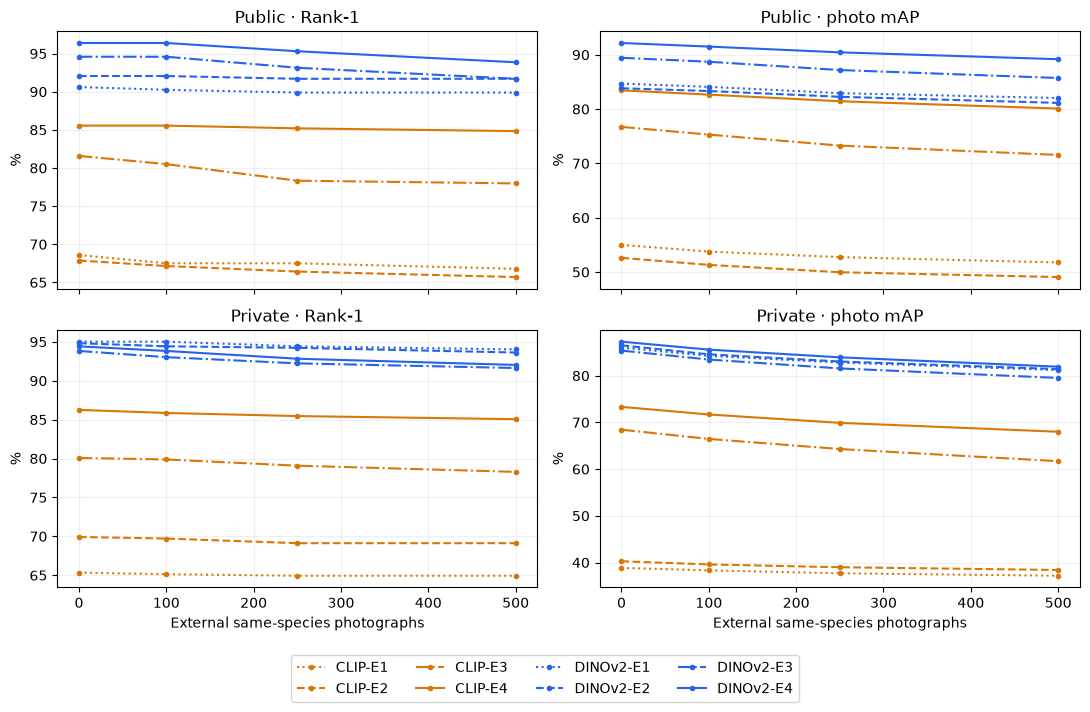

🏃 View run Oxford external distractors · CLIP/DINO E1–E4 at: https://ml.pettrace.app/#/experiments/3/runs/daba7785305f4da08200005788e9bc5e
🧪 View experiment at: https://ml.pettrace.app/#/experiments/3


{'run_id': 'daba7785305f4da08200005788e9bc5e', 'input_sha256': '43c5d391994bb14d10f9a03edccbe8c8f63bfbb8099a4f4d04806b7e967232e6', 'published': True, 'url': 'https://ml.pettrace.app/#/experiments/3/runs/daba7785305f4da08200005788e9bc5e', 'results_sha256': '234b81d888edf5e15e76ad163b76c186b95d1eb3776ab547aa6486b7f2fb1ac1'}


In [5]:
import matplotlib.pyplot as plt
fig, axes=plt.subplots(2,2,figsize=(11,7),sharex=True)
colors={'CLIP':'#d97706','DINOv2':'#2563eb'}
styles={'E1':':','E2':'--','E3':'-.','E4':'-'}
for row,domain in enumerate(('public','private')):
    for col,metric in enumerate(('rank1','mAP')):
        ax=axes[row,col]
        for name in sorted(embeddings):
            encoder,stage=name.split('-')
            ax.plot([0,100,250,500],[100*results[name+'/'+domain][str(k)]['test']['global'][metric] for k in (0,100,250,500)],label=name,color=colors[encoder],linestyle=styles[stage],marker='o',markersize=3)
        ax.set_title(domain.title()+' · '+('Rank-1' if metric=='rank1' else 'photo mAP'))
        ax.set_ylabel('%');ax.grid(alpha=.2)
        if row==1:ax.set_xlabel('External same-species photographs')
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=4,bbox_to_anchor=(.5,-.02))
fig.tight_layout(rect=(0,.07,1,1));fig.savefig(REPORT/'curves.png',dpi=180,bbox_inches='tight')
plt.show()
# Retry this publication cell without extracting features again.
for key,levels in results.items():
    for count,ev in levels.items():
        for scope in ('global','cat','dog'):
            for metric in ('rank1','mAP','external_top1'):
                client.log_metric(run_id,f"{key.replace('/','.')}.{scope}.n{count}.{metric}",ev['test'][scope][metric])
for name in ('results.json','reproduction.json','comparisons.json','models.json','curves.png','protocol-lock.json'):
    client.log_artifact(run_id,str(REPORT/name),'report')
for path in REPORT.glob('*-provenance.json'):client.log_artifact(run_id,str(path),'report/provenance')
client.log_artifact(run_id,str(ROOT/'datasets/prepare_oxford_distractors.py'),'source')
client.set_terminated(run_id,status='FINISHED')
assert client.get_run(run_id).info.status=='FINISHED'
publication.update(published=True,url=f'https://ml.pettrace.app/#/experiments/{experiment.experiment_id}/runs/{run_id}',results_sha256=sha256(REPORT/'results.json'))
receipt_path.write_text(json.dumps(publication,indent=2));client.log_artifact(run_id,str(receipt_path),'report')
print(publication)
